# Mixed layer depth in the Southern Ocean

This recipe looks at the mixed layer depth (MLD) around Antarctica in ACCESS-OM2-01. We:

1. load the model's own MLD diagnostic, `mld`, and map its late-summer and late-winter climatology;
2. average it over six sectors of the Southern Ocean to compare their seasonal cycles;
3. recompute the MLD offline from monthly-mean potential density, and compare it with the model diagnostic.

This recipe is based on a contribution by Natalia Ribeiro ([#400](https://github.com/COSIMA/cosima-recipes/pull/400)), which simplified [code by Denisse Fierro Arcos](https://github.com/lidefi87/ACCESS_scripts_DFA/blob/main/Scripts/Stephy/MLD_calc_Denisse.ipynb).

#### Adapting for MOM6

ACCESS-OM3 (MOM6) saves the mixed layer depth as `mlotst` (on `xh`, `yh`), with the cell area in `areacello` and potential density as `sigma0` (if saved; or compute it from `thetao` and `so`). The MLD criterion MOM6 uses for `mlotst` differs in detail from MOM5's (see below), so check the diagnostic's attributes. The rest of the recipe works the same way.

## Load the data

In [1]:
import cartopy.crs as ccrs
import cartopy.feature as cft
import cmocean as cm
import intake
import matplotlib.path as mpath
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

from dask.distributed import Client

In [2]:
client = Client(threads_per_worker=1)
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 28
Total threads: 28,Total memory: 112.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:33797,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:42431,Total threads: 1
Dashboard: http://127.0.0.1:37727/status,Memory: 4.00 GiB
Nanny: tcp://127.0.0.1:43765,


We use the third cycle of the 0.1° interannually forced run, and a 10-year climatology. The output is in quarterly files, so we restrict the catalog search to the files that start in those years; this avoids opening every file of the experiment.

In [3]:
catalog = intake.cat.access_nri
experiment = '01deg_jra55v140_iaf_cycle3'
cat = catalog[experiment]

start_year, end_year = 2009, 2018
years = '|'.join(str(y) for y in range(start_year, end_year + 1))

lat_north = -50   # northern edge of the region we look at

In [4]:
mld = (cat.search(variable='mld', frequency='1mon', start_date=f'({years}).*')
          .to_dask(xarray_open_kwargs={'decode_timedelta': False})['mld']
          .sel(time=slice(str(start_year), str(end_year)), yt_ocean=slice(None, lat_north)))
mld

<xarray.DataArray 'mld' (time: 120, yt_ocean: 666, xt_ocean: 3600)> Size: 1GB
dask.array<getitem, shape=(120, 666, 3600), dtype=float32, chunksize=(3, 666, 3600), chunktype=numpy.ndarray>
Coordinates:
  * time      (time) datetime64[ns] 960B 2009-01-16T12:00:00 ... 2018-12-16T1...
  * yt_ocean  (yt_ocean) float64 5kB -81.11 -81.07 -81.02 ... -50.09 -50.03
  * xt_ocean  (xt_ocean) float64 29kB -279.9 -279.8 -279.7 ... 79.75 79.85 79.95
Attributes:
    long_name:      mixed layer depth determined by density criteria
    units:          m
    valid_range:    [0.e+00 1.e+06]
    cell_methods:   time: mean
    time_avg_info:  average_T1,average_T2,average_DT
    standard_name:  ocean_mixed_layer_thickness_defined_by_sigma_t

In [5]:
area_search = cat.search(variable='area_t', frequency='fx')
area = xr.open_dataset(area_search.df.path[0])['area_t'].sel(yt_ocean=slice(None, lat_north))

MOM5 diagnoses `mld` every time step as the depth where the buoyancy difference from the surface level reaches $0.0003$ m s$^{-2}$, which corresponds to a density difference of about $0.03$ kg m$^{-3}$ (see `calc_mixed_layer_depth` in [`ocean_tracer_diag.F90`](https://github.com/mom-ocean/MOM5/blob/master/src/mom5/ocean_diag/ocean_tracer_diag.F90)). Where the column is mixed all the way down, `mld` is the depth of the ocean bottom. The monthly output is the average of these values over the month.

We compute the monthly climatology:

In [6]:
mld_clim = mld.groupby('time.month').mean('time').load()

## Late summer and late winter

The mixed layer is shallowest in late summer and deepest in late winter. Here are February and September:

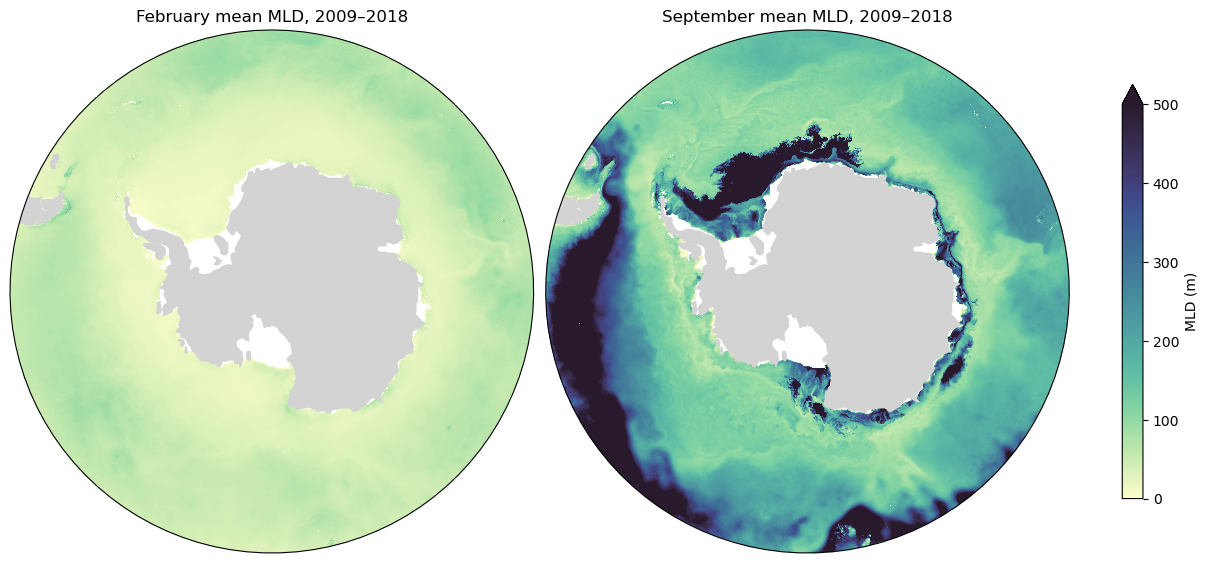

In [7]:
def circular_boundary(ax):
    """Make a south-polar map circular."""
    theta = np.linspace(0, 2 * np.pi, 100)
    verts = np.vstack([np.sin(theta), np.cos(theta)]).T
    ax.set_boundary(mpath.Path(verts * 0.5 + 0.5), transform=ax.transAxes)

fig, axs = plt.subplots(1, 2, figsize=(12, 6), layout='constrained',
                        subplot_kw={'projection': ccrs.SouthPolarStereo()})
for ax, month, name in zip(axs, [2, 9], ['February', 'September']):
    ax.set_extent([-180, 180, -90, lat_north], crs=ccrs.PlateCarree())
    circular_boundary(ax)
    p = mld_clim.sel(month=month).plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cm.cm.deep,
                                       vmin=0, vmax=500, add_colorbar=False)
    ax.add_feature(cft.LAND, color='lightgrey', zorder=2)
    ax.set_title(f'{name} mean MLD, {start_year}–{end_year}')
fig.colorbar(p, ax=axs, shrink=0.7, extend='max', label='MLD (m)');

## Seasonal cycle in Southern Ocean sectors

We divide the Southern Ocean into six sectors, each extending from the Antarctic coast north to roughly the edge of the winter sea ice. The longitudes are in the model's convention, which runs from $-280$ to $80$°E.

In [8]:
# name: (western longitude, eastern longitude, northern latitude)
sectors = {
    'King Haakon VII':    (-15,   70,  -55),
    'East Antarctic':     ( 70, -210,  -57),   # crosses the model's longitude seam at 80°E
    'Ross Sea':           (-210, -135, -62),
    'Amundsen Sea':       (-135,  -90, -63),
    'Bellingshausen Sea': ( -90,  -60, -60),
    'Weddell Sea':        ( -60,  -15, -58),
}

def sector_mask(da, west, east, north):
    """True in the sector: longitudes from west to east (wrapping if needed), south of north."""
    lon, lat = da.xt_ocean, da.yt_ocean
    in_lon = (lon >= west) & (lon < east) if west < east else (lon >= west) | (lon < east)
    return in_lon & (lat <= north)

def sector_mean(da, area, west, east, north):
    """Area-weighted mean of da over the ocean in a sector."""
    mask = sector_mask(da, west, east, north)
    weights = area.where(mask & da.notnull()).fillna(0)
    return da.weighted(weights).mean(['xt_ocean', 'yt_ocean'])

Here are the sectors, overlaid on the September MLD:

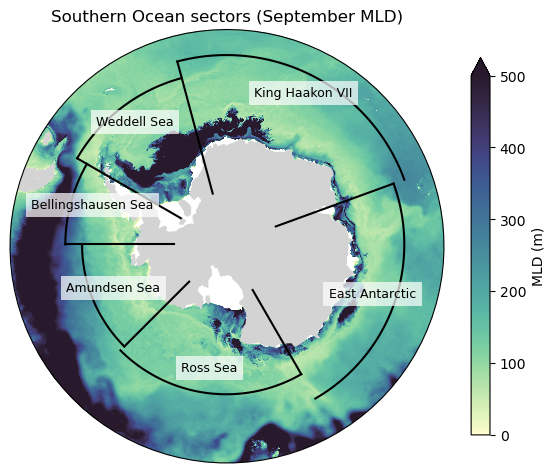

In [9]:
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={'projection': ccrs.SouthPolarStereo()})
ax.set_extent([-180, 180, -90, lat_north], crs=ccrs.PlateCarree())
circular_boundary(ax)
mld_clim.sel(month=9).plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cm.cm.deep, vmin=0, vmax=500,
                           cbar_kwargs={'label': 'MLD (m)', 'shrink': 0.7, 'extend': 'max'})
ax.add_feature(cft.LAND, color='lightgrey', zorder=2)
for name, (west, east, north) in sectors.items():
    ax.plot([west, west], [-80, north], color='k', transform=ccrs.PlateCarree())
    lons = np.linspace(west, east if west < east else east + 360, 50)
    ax.plot(lons, np.full_like(lons, north), color='k', transform=ccrs.PlateCarree())
    mid = (west + (east if west < east else east + 360)) / 2
    ax.text(mid, north - 4, name, transform=ccrs.PlateCarree(), ha='center', fontsize=9,
            bbox=dict(facecolor='white', alpha=0.7, lw=0))
ax.set_title('Southern Ocean sectors (September MLD)');

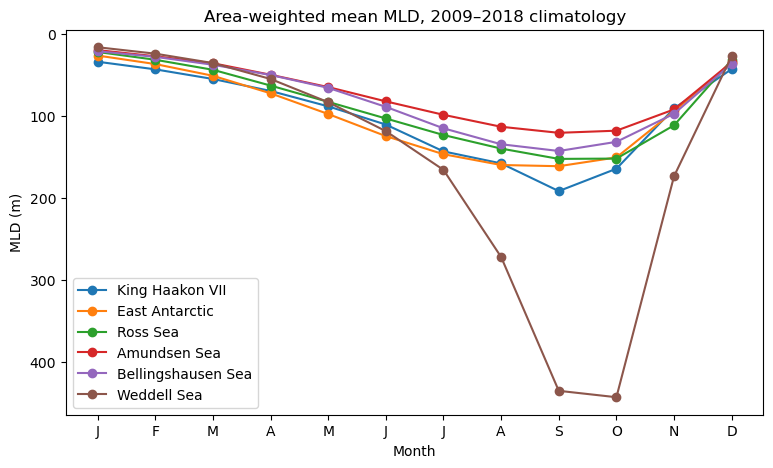

In [10]:
mld_sectors = xr.concat([sector_mean(mld_clim, area, *bounds) for bounds in sectors.values()],
                        dim=xr.DataArray(list(sectors), dims='sector', name='sector'))

fig, ax = plt.subplots(figsize=(9, 5))
for name in sectors:
    mld_sectors.sel(sector=name).plot(ax=ax, label=name, marker='o')
ax.invert_yaxis()
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])
ax.set_xlabel('Month')
ax.set_ylabel('MLD (m)')
ax.set_title(f'Area-weighted mean MLD, {start_year}–{end_year} climatology')
ax.legend();

## Recomputing the MLD from density

Often we want the MLD with a different criterion from the model's, or from a model or observational product that doesn't provide it. Here we compute it from the monthly-mean potential density `pot_rho_0` with the same criterion MOM5 uses: the depth where the density first exceeds the density of the top level by $\Delta\rho = \rho_0 \, b_{crit} / g \approx 0.03$ kg m$^{-3}$, interpolating linearly between levels, or the depth of the deepest ocean level if that never happens. (A common choice in the observational literature is instead $0.03$ kg m$^{-3}$ relative to the density at 10 m; [de Boyer Montégut et al., 2004](https://doi.org/10.1029/2004JC002378).)

The density is 3D, so we only use one year.

In [11]:
year = 2018

rho = (cat.search(variable='pot_rho_0', frequency='1mon', start_date=f'{year}.*')
          .to_dask(xarray_open_kwargs={'decode_timedelta': False})['pot_rho_0']
          .sel(time=str(year), yt_ocean=slice(None, lat_north))
          .chunk({'st_ocean': -1}))
rho

<xarray.DataArray 'pot_rho_0' (time: 12, st_ocean: 75, yt_ocean: 666,
                               xt_ocean: 3600)> Size: 9GB
dask.array<rechunk-merge, shape=(12, 75, 666, 3600), dtype=float32, chunksize=(2, 75, 270, 360), chunktype=numpy.ndarray>
Coordinates:
  * time      (time) datetime64[ns] 96B 2018-01-16T12:00:00 ... 2018-12-16T12...
  * st_ocean  (st_ocean) float64 600B 0.5413 1.681 2.94 ... 5.511e+03 5.709e+03
  * yt_ocean  (yt_ocean) float64 5kB -81.11 -81.07 -81.02 ... -50.09 -50.03
  * xt_ocean  (xt_ocean) float64 29kB -279.9 -279.8 -279.7 ... 79.75 79.85 79.95
Attributes:
    long_name:      potential density referenced to 0 dbar
    units:          kg/m^3
    valid_range:    [-1.e+01  1.e+05]
    cell_methods:   time: mean
    time_avg_info:  average_T1,average_T2,average_DT
    standard_name:  sea_water_potential_density

In [12]:
rho_0 = 1035.0          # reference density (kg m-3)
g = 9.81                # gravitational acceleration (m s-2)
buoyancy_crit = 0.0003  # MOM5's default criterion (m s-2)
drho_crit = rho_0 * buoyancy_crit / g
print(f'density criterion: {drho_crit:.4f} kg m-3')

def mld_from_density(rho, depth, drho_crit):
    """MLD from density profiles along the last axis.

    The depth where rho - rho[top] first reaches drho_crit, interpolated
    linearly between levels, or the deepest ocean level if it never does.
    """
    drho = rho - rho[..., :1]
    exceeds = drho >= drho_crit
    found = exceeds.any(axis=-1)
    k = np.argmax(exceeds, axis=-1)           # first level that exceeds the criterion
    km1 = np.maximum(k - 1, 0)
    d0 = np.take_along_axis(drho, km1[..., None], axis=-1)[..., 0]
    d1 = np.take_along_axis(drho, k[..., None], axis=-1)[..., 0]
    z0, z1 = depth[km1], depth[k]
    with np.errstate(invalid='ignore', divide='ignore'):
        mld = z0 + (z1 - z0) * (drho_crit - d0) / (d1 - d0)
    n_ocean = np.isfinite(rho).sum(axis=-1)
    bottom = depth[np.maximum(n_ocean - 1, 0)]
    mld = np.where(found, mld, bottom)
    return np.where(n_ocean > 0, mld, np.nan)

mld_rho = xr.apply_ufunc(mld_from_density, rho,
                         kwargs={'depth': rho.st_ocean.values, 'drho_crit': drho_crit},
                         input_core_dims=[['st_ocean']],
                         dask='parallelized', output_dtypes=[rho.dtype])
mld_rho = mld_rho.rename('mld_from_density').load()
mld_model = mld.sel(time=str(year)).load()

density criterion: 0.0317 kg m-3


### Comparison with the model diagnostic

In most sectors the two follow the same seasonal cycle, with the MLD computed from monthly-mean density a few metres shallower than the model diagnostic (up to about 20 m in winter). The exceptions are the Weddell and Ross Seas in winter, where the model diagnostic is much deeper:

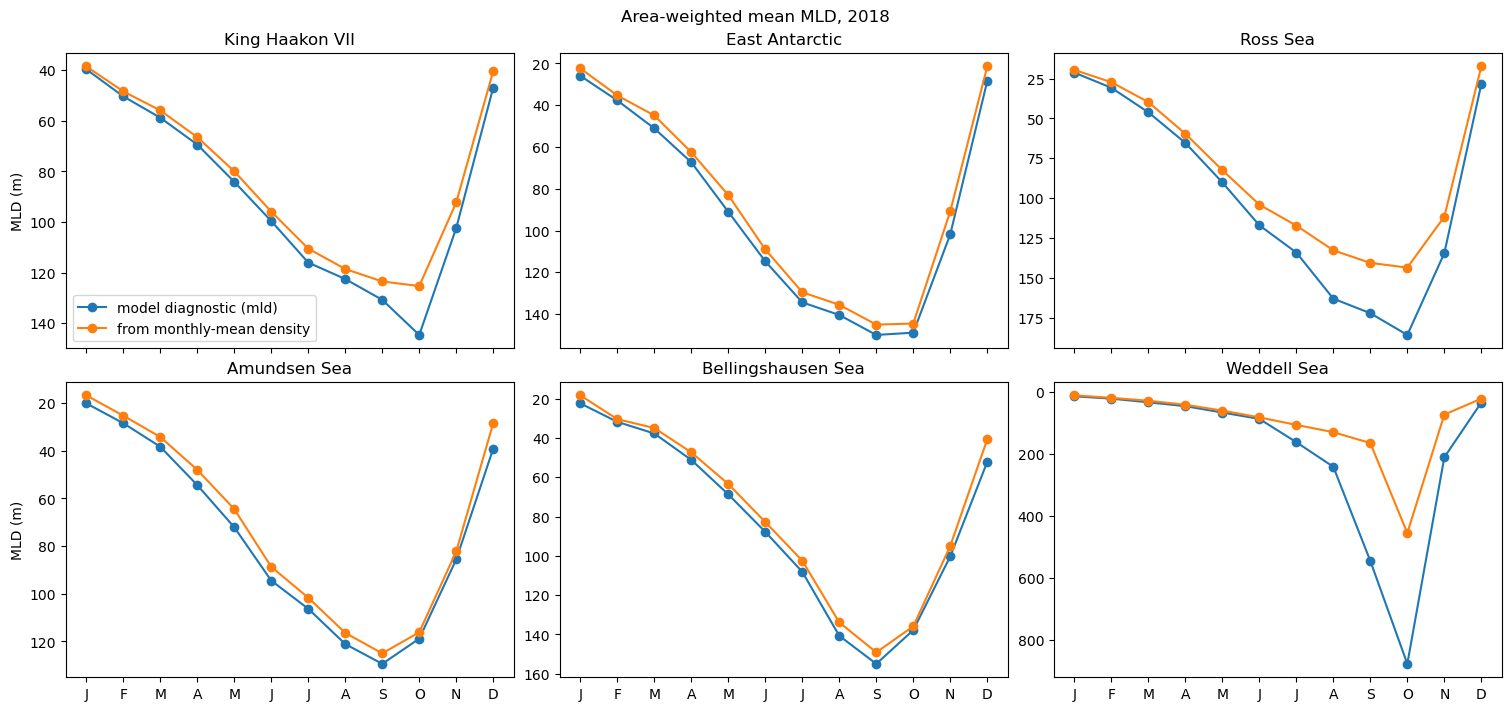

In [13]:
fig, axs = plt.subplots(2, 3, figsize=(15, 7), sharex=True, layout='constrained')
for ax, (name, bounds) in zip(axs.flat, sectors.items()):
    model = sector_mean(mld_model, area, *bounds)
    offline = sector_mean(mld_rho, area, *bounds)
    ax.plot(model.time.dt.month, model, marker='o', label='model diagnostic (mld)')
    ax.plot(offline.time.dt.month, offline, marker='o', label='from monthly-mean density')
    ax.invert_yaxis()
    ax.set_title(name)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])
for ax in axs[:, 0]:
    ax.set_ylabel('MLD (m)')
axs[0, 0].legend()
fig.suptitle(f'Area-weighted mean MLD, {year}');

Mapping September shows where they differ:

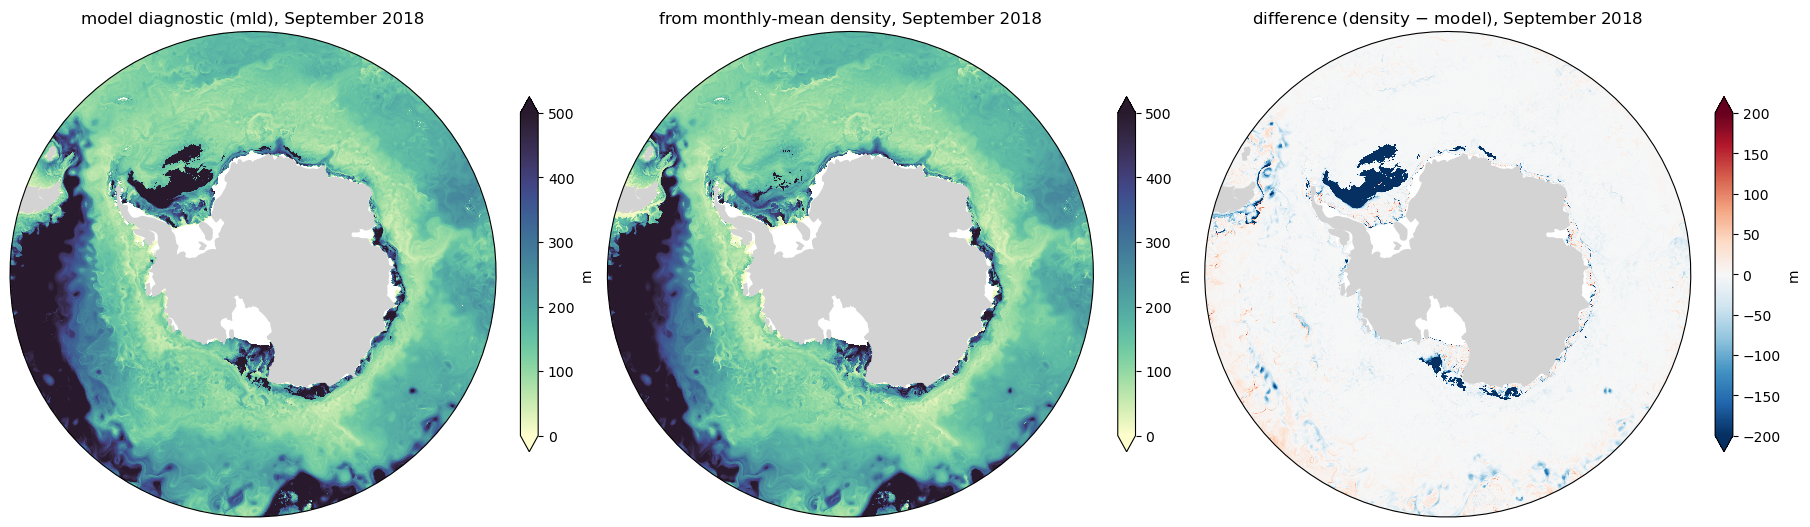

In [14]:
september = {'model diagnostic (mld)': mld_model.sel(time=f'{year}-09').squeeze(),
             'from monthly-mean density': mld_rho.sel(time=f'{year}-09').squeeze()}
september['difference (density $-$ model)'] = (september['from monthly-mean density']
                                                - september['model diagnostic (mld)'])

fig, axs = plt.subplots(1, 3, figsize=(18, 6), layout='constrained',
                        subplot_kw={'projection': ccrs.SouthPolarStereo()})
for ax, (title, da) in zip(axs, september.items()):
    ax.set_extent([-180, 180, -90, lat_north], crs=ccrs.PlateCarree())
    circular_boundary(ax)
    if title.startswith('difference'):
        kwargs = dict(cmap='RdBu_r', vmin=-200, vmax=200)
    else:
        kwargs = dict(cmap=cm.cm.deep, vmin=0, vmax=500)
    da.plot(ax=ax, transform=ccrs.PlateCarree(), **kwargs,
            cbar_kwargs={'label': 'm', 'shrink': 0.6, 'extend': 'both'})
    ax.add_feature(cft.LAND, color='lightgrey', zorder=2)
    ax.set_title(f'{title}, September {year}')

The large differences are on the continental shelves of the Weddell and Ross Seas, where the model's `mld` reaches the sea floor. Elsewhere the two agree to within a few tens of metres.

There are two reasons for the differences:

- **Averaging.** The model diagnoses the MLD every time step and then averages it over the month, whereas we compute it from the *monthly-mean* density. The MLD is a nonlinear function of the density profile, so the two don't commute. For example, if the water column on the shelf is mixed to the sea floor for part of the month, the monthly-mean `mld` is deep, but the monthly-mean density profile can still be stratified enough to give a much shallower MLD.
- **Details of the criterion.** The model compares the in-situ density at each level with the density that surface water would have at the same pressure, while we use potential density referenced to the surface (`pot_rho_0`), and the model takes the depth of the ocean bottom (not the deepest tracer level) when the column is fully mixed.

So, if you need the MLD that the model itself experienced, use the model's diagnostic. Recomputing it from monthly-mean density is useful when you need a particular criterion, for example to compare with observations, but expect it to be shallower where the mixed layer deepens only for part of the month, such as during convection on the continental shelf.